Combining Focal and Dice is straightforward. Here is a set up for a 6-class Potsdam U-Net problem, using the popular ``segmentation_models_pytorch`` (SMP) library or a custom formulation

The implementation snippet provided below is designed specifically for target labels that are a single-dimensional channel filled with integer values (representing your 6 classes).



### One Important Catch: Check Your Output Layer

- Ensure that your U-Net does not apply a Softmax or Sigmoid activation function at the very end of your network definition. Both ``FocalLoss`` and ``DiceLoss`` from the library expect **raw logits** (unnormalized network outputs). They apply the internal mathematical activations themselves to ensure numerical stability.

In [1]:
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

# distribution of each class in the training dataset

dist = {
    0: 0.2846,  # Impervious surfaces
    1: 0.2672,  # Building
    2: 0.2354,  # Low vegetation
    3: 0.1462,  # Tree
    4: 0.0166,   # Car
    5: 0.0499,    # Clutter/background
}

raw_inverse = torch.tensor([1.0 / dist[i] for i in range(6)], dtype=torch.float32)

sqrt_weights = torch.sqrt(raw_inverse)

smoothed_weights = sqrt_weights / sqrt_weights.min()
smoothed_weights


tensor([1.0000, 1.0320, 1.0995, 1.3952, 4.1406, 2.3882])

## ASPP Module suggestion form Gemini

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ASPPModule(nn.Module):
    def __init__(self, in_channels, out_channels, rates=[6, 12, 18]):
        super(ASPPModule, self).__init__()
        
        # Branch 1: Standard 1x1 Convolution
        self.b1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        
        # Branches 2, 3, 4: Atrous Convolutions with padding matching the dilation rate
        self.b2 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=rates[0], dilation=rates[0], bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        self.b3 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=rates[1], dilation=rates[1], bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        self.b4 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=rates[2], dilation=rates[2], bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        
        # Branch 5: Global Context (Image-level Pooling)
        self.b5 = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
        
        # Project back to desired out_channels (Total branches = 5)
        self.project = nn.Sequential(
            nn.Conv2d(out_channels * 5, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        size = x.shape[-2:]
        feat1 = self.b1(x)
        feat2 = self.b2(x)
        feat3 = self.b3(x)
        feat4 = self.b4(x)
        
        # Global pooling branch needs upsampling back to feature map size
        feat5 = self.b5(x)
        feat5 = F.interpolate(feat5, size=size, mode='bilinear', align_corners=False)
        
        # Concat along channel dimension and project
        out = torch.cat([feat1, feat2, feat3, feat4, feat5], dim=1)
        return self.project(out)

# --- U-Net Insertion Example ---
# inside your UNet's forward pass:
# x1 = encoder_layer1(x)
# x2 = encoder_layer2(x1)
# ...
# bridge = self.aspp(x_deepest)  <-- Insert ASPP right here before decoding
# ...
# decoder_out = decoder_layer1(bridge, x_skip_connection)

## Import packages

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

import segmentation_models_pytorch as smp

import tifffile as tiff
from pathlib import Path


In [3]:
print("segmentation_models_pytorch version:", smp.__version__)

# FocalLoss in version 0.5.0 strictly expects raw logits

segmentation_models_pytorch version: 0.5.0


In [4]:
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA Version:", torch.version.cuda)

PyTorch Version: 2.3.1+cu118
CUDA Available: True
CUDA Version: 11.8


## Build vanilla U-Net model for semantic segmentation 

PyTorch expects images in (channels × height × width) format, or (C, H, W).
- Single Image: (C, H, W) — for example, a 3-channel RGB image is ``(3, H, W)``.
- Batch of Images: ``(B, C, H, W)`` — where B is the batch size

- Unlike libraries like Matplotlib, OpenCV, or NumPy/PIL arrays which typically use (H, W, C) (channels-last), PyTorch standardizes on "channels-first" (C, H, W) for its convolutional layers and transforms.

- How to convert: If you have an image array shaped as (H, W, C) (such as from NumPy or Matplotlib), you can switch it to PyTorch format using ``.permute(2, 0, 1)``

## Model architecture

- Design follows the original U-Net architecture with the exception that the downsampling are done in three stages instead of four, and the upsampling is done in three stages as well.
- This choice was made in order to have less parameters to train.

In [5]:
class Vanilla_UNet(nn.Module):

    def __init__(self, img_dim:int, n_class:int, in_channels:int=3):

        super().__init__()
        
        self.n_class = n_class
        self.in_channels = in_channels
        self.out_channels = n_class
        self.img_dim = img_dim

        if self.img_dim  < 256:
            raise ValueError("Image dimension must be at least 256x256 for this U-Net implementation.")
        if self.img_dim % 256 != 0:
            raise ValueError("Image dimension must be a multiple of 256 for this U-Net implementation.")


        # Define the U-Net model using torch.nn


        # ---- MAXPOOLING ----
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)



        # ---- ENCODER ----
        
        # output used in skip connection
        self.encode_1 = nn.Sequential(
            nn.Conv2d(self.in_channels, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))
        
        # output used in skip connection
        self.encode_2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))
        
        # output used in skip connection
        self.encode_3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- BRIDGE ---- 
        # to connect encoder and decoder
        self.bridge = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- UP-SAMPLING ----
        # Upconvolution layers to upsample the feature maps back to the original image size
        self.upconv_3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)   # increase the spatial dimensions (64 --> 128)
        self.upconv_2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)   # increase the spatial dimensions (128 --> 256)
        self.upconv_1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)    # increase the spatial dimensions (256 --> 512)



        # ---- DECODER -----
        self.decode_3 = nn.Sequential(
            nn.Conv2d(512, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))

        self.decode_2 = nn.Sequential(
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))

        self.decode_1 = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True))



        # ---- FINAL CONVOLUTION LAYER ----
        # Final layer to map to the desired number of classes
        self.final_conv = nn.Conv2d(64, self.out_channels, kernel_size=1)  




    def forward(self, x):

        # --- Encoder ---
        encoded_1 = self.encode_1(x)

        x = self.maxpool(encoded_1)

        encoded_2 = self.encode_2(x)

        x = self.maxpool(encoded_2)

        encoded_3 = self.encode_3(x)

        x = self.maxpool(encoded_3)



        # --- Bridge ---
        x = self.bridge(x)



        # --- Decoder ---
        
        # increase the spatial dimensions (64 --> 128)
        # decrease the number of channels (512 --> 256)
        x = self.upconv_3(x) 
        # Concatenate along the channel dimension 
        # dim=1 since PyTorch uses (N,C,H,W) format, where N is batch size, C is channels, H is height, W is width
        # number of channels after concatenation will be 256 (from upconv_3) + 256 (from encoded_3) = 512
        x = torch.cat((encoded_3, x), dim=1)

        x = self.decode_3(x)



        # increase the spatial dimensions (128 --> 256)
        # decrease the number of channels (256 --> 128)
        x = self.upconv_2(x)
        # number of channels after concatenation will be 128 (from upconv_2) + 128 (from encoded_2) = 256
        x = torch.cat((encoded_2, x), dim=1)
        
        x = self.decode_2(x)



        # increase the spatial dimensions (256 --> 512)
        # decrease the number of channels (128 --> 64)
        x = self.upconv_1(x)

        # number of channels after concatenation will be 64 (from upconv_1) + 64 (from encoded_1) = 128
        x = torch.cat((encoded_1, x), dim=1)
        
        x = self.decode_1(x)



        # --- Final layer --- 
        # to map to the desired number of classes
        x = self.final_conv(x)

        return x


# Initialize datasets and dataloaders

In [6]:
from torchvision.transforms import Compose, ToTensor

from PotsdamDataset import PotsdamDataset

import albumentations as A

train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5), ])

In [7]:

small_train_dataset = PotsdamDataset(root="./small_train_patches", transform=train_transform)
small_val_dataset = PotsdamDataset(root="./small_val_patches", transform=None)

small_train_loader = DataLoader(small_train_dataset, batch_size=16, shuffle=True, num_workers=4, pin_memory=True)
small_val_loader = DataLoader(small_val_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=True)

In [8]:
print(f"The example dataset is: {small_train_dataset}")
print(f"The example dataset type is: {type(small_train_dataset)}")
number_of_samples = len(small_train_dataset)
print(f"The number of samples is: {number_of_samples}")

img, label = small_train_dataset[200]

print(type(img), type(label))
print(img.dtype, label.dtype)
print(img.shape, label.shape)



The example dataset is: <PotsdamDataset.PotsdamDataset object at 0x7852b7bb5b10>
The example dataset type is: <class 'PotsdamDataset.PotsdamDataset'>
The number of samples is: 350
<class 'torch.Tensor'> <class 'torch.Tensor'>
torch.float32 torch.int64
torch.Size([3, 512, 512]) torch.Size([512, 512])


Image shape: torch.Size([3, 512, 512])  
Label shape: torch.Size([512, 512])


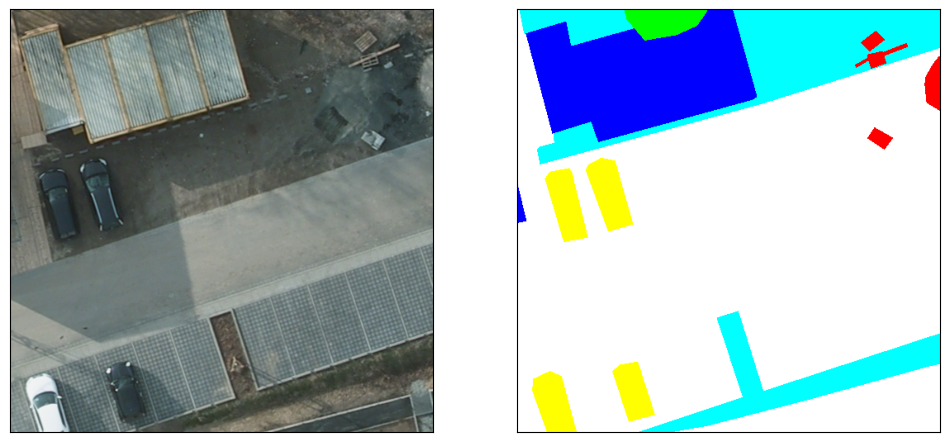

In [11]:
from plot_functions import display_image_tensor

img, label = small_train_dataset[21]

print(f"Image shape: {img.shape}  \nLabel shape: {label.shape}")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
display_image_tensor(axes[0], img)
display_image_tensor(axes[1], label)


Text(0.5, 1.0, 'Ground Truth')

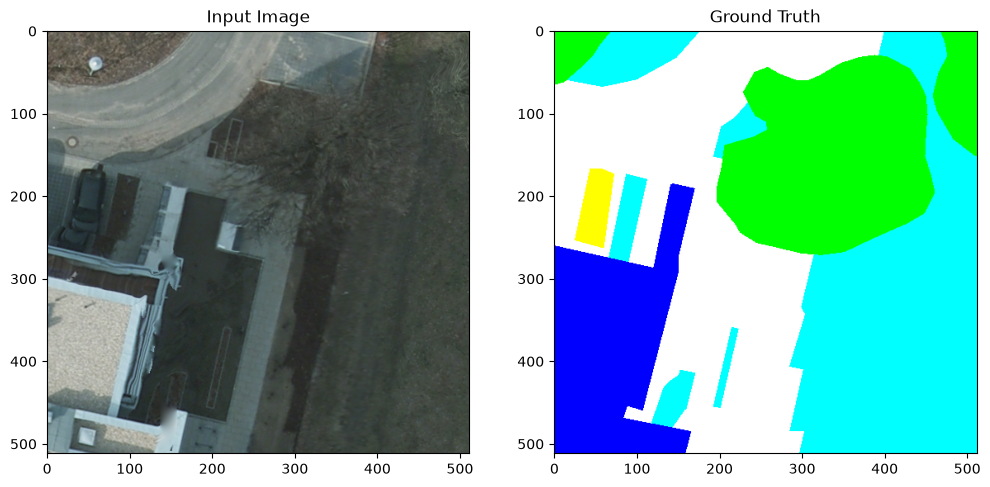

In [12]:
img, label = small_train_dataset.get_tif_by_id("2_12_512_1024")

plt.subplots(1, 2, figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title('Input Image')
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(label)
plt.title('Ground Truth')

# Training starts

In [13]:
from training_loop import DiceFocalLoss, output_to_label, training_loop, train_epoch, validate

In [14]:
model = Vanilla_UNet(img_dim=512, n_class=6, in_channels=3)
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = DiceFocalLoss(w1=1, w2=1)
num_epochs = 20



# model, train_losses, train_accs, val_losses, val_accs
model, train_metrics, val_metrics = training_loop(
        model, optimizer, loss_fn, small_train_loader, small_val_loader, num_epochs, print_every=None)

Starting training


/home/edvard_edsgard/conda/envs/dml/lib/python3.11/site-packages/torch/nn/modules/conv.py:456: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:84.)
  return F.conv2d(input, weight, bias, self.stride,


Batch 1/22 completed
Batch 2/22 completed
Batch 3/22 completed
Batch 4/22 completed
Batch 5/22 completed
Batch 6/22 completed
Batch 7/22 completed
Batch 8/22 completed
Batch 9/22 completed
Batch 10/22 completed
Batch 11/22 completed
Batch 12/22 completed
Batch 13/22 completed
Batch 14/22 completed
Batch 15/22 completed
Batch 16/22 completed
Batch 17/22 completed
Batch 18/22 completed
Batch 19/22 completed
Batch 20/22 completed
Batch 21/22 completed
Batch 22/22 completed
Epoch 1/20: Avg. Train loss: 3.051, Train mean IoU: 0.068
Val. loss: 3.182, Val. mean IoU: 0.031

Per-class IoU of Validation Set:
  -> Class 0 IoU: 0.0000
  -> Class 1 IoU: 0.1830
  -> Class 2 IoU: 0.0052
  -> Class 3 IoU: 0.0000
  -> Class 4 IoU: 0.0000
  -> Class 5 IoU: 0.0000
Batch 1/22 completed
Batch 2/22 completed
Batch 3/22 completed
Batch 4/22 completed
Batch 5/22 completed
Batch 6/22 completed
Batch 7/22 completed
Batch 8/22 completed
Batch 9/22 completed
Batch 10/22 completed
Batch 11/22 completed
Batch 12/22

torch.Size([3, 512, 512])
torch.Size([512, 512])


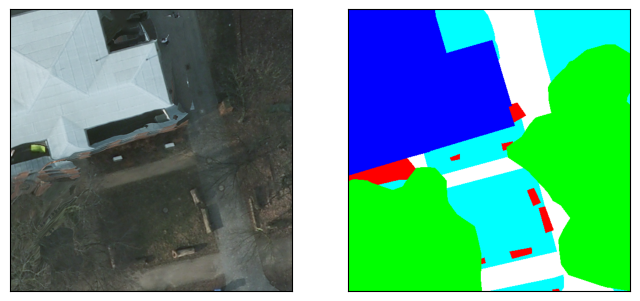

In [71]:
img, label = small_val_dataset[5]

fig, axes = plt.subplots(1, 2, figsize=(8, 5))
display_image_tensor(axes[0], img)
display_image_tensor(axes[1], label)

print(img.shape)
print(label.shape)

In [68]:
from convert_labels import from_int_labels_to_rgb
from plot_functions import display_image_tensor

def display_prediction(model, img, label, fig_size=(14, 7)):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    # img needs to be in format ([1, 3, 512, 512])
    if img.ndim == 4 and img.shape[0] == 1:
        pass
    elif img.ndim == 3 and img.shape[0] == 3:
        img = img.unsqueeze(0) #add a first dimension
    else:
        raise ValueError("Wrong format of image - it needs to be in PyTorch Tensor format.")

    logits = model.forward(img.to(device))
    
    hard_preds = output_to_label(logits)
    hard_preds = hard_preds.squeeze(0).cpu().numpy()
    
    color_preds = from_int_labels_to_rgb(hard_preds)


    fig, axis = plt.subplots(1, 3, figsize=fig_size)

    display_image_tensor(axis[0], img.squeeze(0))
    axis[0].set_title("Input Image")

    display_image_tensor(axis[1], label)
    axis[1].set_title("True Labels")
    
    axis[2].imshow(color_preds)
    axis[2].set_title('Prediction')
    axis[2].set_xticks([])
    axis[2].set_yticks([])
    
    plt.show()
    
    

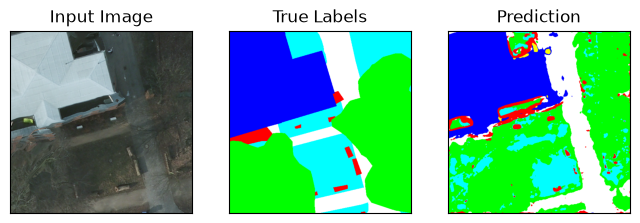

In [70]:
display_prediction(model, img, label, fig_size=(8,5))

In [73]:
train_metrics.keys()

dict_keys(['loss', 'miou', 'f1_macro', 'accuracy'])

In [74]:
type(train_metrics['miou'])

list